# Session 02 · Part 1 — The agent loop, written two ways

You build the **research step** of the Research Brief Agent twice:

1. **By hand with LangGraph**: a `StateGraph` with two nodes (`llm_call`, `tool_node`) and one conditional edge.
   This is the Thought → Action → Observation loop from Session 01, written as code.
2. **With LangChain `create_agent`**: the same loop, already packaged.

Then you put the loop inside a `research_agent` node of an outer graph. Part 2 adds persistence, streaming and human review.

**Why rebuild the loop by hand?** From Session 03 on, the course builds on `create_agent` and Deep Agents; you will not
write LangGraph loops again. Part A is here to show what those agents do inside, so the hand-built loop mirrors
`create_agent`: same tools, same system prompt, tool calls run in parallel, and the same config (`recursion_limit`).

<img src="images/agent_loop.png" width="480">

The agent searches the web and reads pages with [Tavily](https://docs.tavily.com/).
Run it with the **venvAE02** kernel and the keys in this session's `.env` (setup: the session README).
The outputs below come from a real run; yours will differ a little because the model and the search results change.

References: [LangGraph quickstart](https://docs.langchain.com/oss/python/langgraph/quickstart) ·
[Graph API](https://docs.langchain.com/oss/python/langgraph/graph-api) ·
[LangChain agents](https://docs.langchain.com/oss/python/langchain/agents) ·
[LangChain tools](https://docs.langchain.com/oss/python/langchain/tools)

## 0. Setup
`init_chat_model` takes a `provider:model` string, so you can switch provider in `.env` without changing code.

In [1]:
import logging
import os

from dotenv import load_dotenv
from langchain.chat_models import init_chat_model

logging.basicConfig(level=logging.INFO, format="%(levelname)s | %(message)s")
for noisy in ("httpx", "httpx2"):  # HTTP clients log every request at INFO
    logging.getLogger(noisy).setLevel(logging.WARNING)
logger = logging.getLogger(__name__)

# ── Keys and model (.env of this session folder) ─────────────────────────────
load_dotenv()
for name in ("OPENAI_API_KEY", "TAVILY_API_KEY"):
    if not os.getenv(name, "").strip():
        raise RuntimeError(f"Missing {name}: copy .env.example to .env in the session folder and fill it in")

model = init_chat_model(os.getenv("MODEL", "openai:gpt-6-luna"))
logger.info("Model: %s", model.model_name)

INFO | Model: gpt-6-luna


## 1. Tools

A tool is a Python function with a name, a docstring and typed arguments. `@tool` turns it into the JSON schema the model sees,
so the docstring is what the model reads to decide when to call it.

- `search_docs(query)` finds documents on the web (Tavily Search).
- `read_doc(url, question)` returns the parts of a page that answer the question (Tavily Extract).
  A url Tavily rejects comes back as an `ERROR: ...` text, so the model can choose another page. Network errors are not
  caught here: they are transient, and Part 2 retries them with `RetryPolicy`.

In [2]:
# ── Tools: web search and page reading with Tavily ───────────────────────────
from langchain.tools import tool
from tavily import BadRequestError, TavilyClient

tavily = TavilyClient()  # uses TAVILY_API_KEY


@tool
def search_docs(query: str) -> list[dict]:
    """Search the web for documents about the query. Returns the title and url of the top 3 results."""
    hits = tavily.search(query, max_results=3)["results"]
    return [{"title": h["title"], "url": h["url"]} for h in hits]


@tool
def read_doc(url: str, question: str) -> str:
    """Read the parts of one document (a web page from search_docs) that answer the question."""
    try:
        pages = tavily.extract(urls=[url], query=question, chunks_per_source=3)["results"]
    except BadRequestError as error:  # bad input: tell the model so it can pick another page
        return f"ERROR: could not read {url} ({error})"
    return pages[0]["raw_content"] if pages else f"ERROR: could not read {url}"

Call the tools yourself first: this is exactly what the agent will receive as an Observation.

In [3]:
hits = search_docs.invoke({"query": "how do heat pumps work"})
print(hits)
print(read_doc.invoke({"url": hits[0]["url"], "question": "How does a heat pump move heat?"})[:500])

[{'title': 'How do heat pumps work? | National Grid', 'url': 'https://www.nationalgrid.com/stories/energy-explained/how-do-heat-pumps-work'}, {'title': 'What Is A Heat Pump And How Does It Work? | Carrier', 'url': 'https://www.carrier.com/us/en/residential/hvac-resources/heat-pumps/what-is-a-heat-pump-how-does-it-work'}, {'title': 'How a heat pump works – The Future of Heat Pumps – Analysis - IEA', 'url': 'https://www.iea.org/reports/the-future-of-heat-pumps/how-a-heat-pump-works'}]


What to do if you smell gas

## How do heat pumps work?

A heat pump uses electricity to provide both heating and cooling to a building. These appliances are efficient at transferring heat from one place to another, depending on where it’s needed.

​In the winter, a heat pump provides heating by extracting heat from outside a building and moving it inside. In the summer, it can provide cooling by moving heat from indoors to the outside.

Find out about the different types of heat pumps, how they


In [4]:
SYSTEM_PROMPT = (
    "You write short research briefs (under 250 words) from sources you read with the tools only. "
    "Call independent tools together in one turn (several searches, or several pages to read), "
    "and read two or three different pages before writing; prefer official or primary sources. "
    "Cite every point with the url you read. If the sources do not answer, say so; never invent facts or urls. "
    "End with the brief itself, no follow-up offers."
)

## 2. Part A — the loop by hand

**State**: only the message list. `operator.add` is its reducer, so every node *appends* its messages.

In [5]:
import operator
from typing import Annotated
from typing_extensions import TypedDict
from langchain.messages import AnyMessage


class LoopState(TypedDict):
    messages: Annotated[list[AnyMessage], operator.add]

**Thought**: `llm_call` sends the messages to the model bound to the tools. The model answers or asks for tool calls.

In [6]:
from langchain.messages import SystemMessage

tools = [search_docs, read_doc]
tools_by_name = {t.name: t for t in tools}
model_with_tools = model.bind_tools(tools)


def llm_call(state: LoopState) -> dict:
    response = model_with_tools.invoke([SystemMessage(SYSTEM_PROMPT)] + state["messages"])
    logger.info("llm_call → %s", f"{len(response.tool_calls)} tool call(s)" if response.tool_calls else "answer")
    return {"messages": [response]}

**Action → Observation**: `tool_node` runs **one** tool call and returns its `ToolMessage`.

Design: a model turn often asks for several tools at once (three searches, or two pages to read). Instead of looping over
them inside one node, the edge below sends each call to its own `tool_node` task with
[`Send`](https://docs.langchain.com/oss/python/langgraph/graph-api#send). Tasks created in the same step run **in parallel**,
and the next `llm_call` sees all results together. `create_agent` runs its tools exactly this way.

In [7]:
from langchain.messages import ToolMessage


def tool_node(tool_call: dict) -> dict:
    """Run ONE tool call. The input is the Send payload (a tool call), not the whole state."""
    logger.info("tool_node → %s(%s)", tool_call["name"], tool_call["args"])
    observation = tools_by_name[tool_call["name"]].invoke(tool_call["args"])
    return {"messages": [ToolMessage(content=str(observation), tool_call_id=tool_call["id"])]}

**Routing and stop condition**: after each model turn, `should_continue` ends the run (no tool calls: the model answered)
or fans out one `Send` per tool call. There is no step counter in the state: as with `create_agent`, the run is bounded by
`recursion_limit` in the config. A model turn plus its parallel tool step is two steps, so `20` allows about 10 rounds.

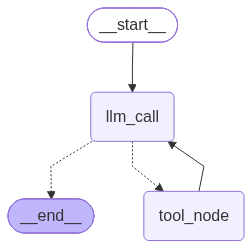

In [8]:
from typing import Literal
from IPython.display import Image
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send

CONFIG = {"recursion_limit": 20}


def should_continue(state: LoopState) -> list[Send] | Literal["__end__"]:
    tool_calls = state["messages"][-1].tool_calls
    if not tool_calls:  # the model answered: stop
        return END
    # Fan out: one tool_node task per call, all in the same step, so they run in parallel.
    # Their ToolMessages are appended (operator.add) before llm_call runs again.
    return [Send("tool_node", call) for call in tool_calls]


builder = StateGraph(LoopState)
builder.add_node("llm_call", llm_call)    # create_agent calls this node "model"
builder.add_node("tool_node", tool_node)  # ... and this one "tools"
builder.add_edge(START, "llm_call")
builder.add_conditional_edges("llm_call", should_continue, ["tool_node", END])
builder.add_edge("tool_node", "llm_call")
loop = builder.compile()
Image(loop.get_graph().draw_mermaid_png())

Run it. The log lines are the Thought → Action → Observation trace; the cell prints the final answer.

In [9]:
from langchain.messages import HumanMessage

QUESTION = "When should a small team choose PostgreSQL instead of SQLite?"
result = loop.invoke({"messages": [HumanMessage(QUESTION)]}, CONFIG)
print(result["messages"][-1].text)

INFO | llm_call → 3 tool call(s)


INFO | tool_node → search_docs({'query': 'PostgreSQL official documentation concurrency MVCC multiple sessions SQLite appropriate uses'})


INFO | tool_node → search_docs({'query': 'SQLite official when to use SQLite client server concurrent writers'})


INFO | tool_node → search_docs({'query': 'PostgreSQL official documentation client server architecture multiple users'})


INFO | llm_call → 3 tool call(s)


INFO | tool_node → read_doc({'url': 'https://www.sqlite.org/whentouse.html', 'question': 'When does SQLite recommend itself, and when does it recommend client/server database? Include concurrency limits.'})


INFO | tool_node → read_doc({'url': 'https://www.postgresql.org/docs/current/tutorial-arch.html', 'question': 'Explain PostgreSQL client-server architecture and multiple client connections.'})


INFO | tool_node → read_doc({'url': 'https://www.postgresql.org/docs/current/mvcc-intro.html', 'question': 'How does PostgreSQL MVCC support concurrent access/readers and writers?'})


INFO | llm_call → answer


Choose PostgreSQL when your team’s needs have outgrown a database file:

- **Writes arrive concurrently.** SQLite permits only one writer at a time per database file. It can work well when writes are brief and can take turns, but SQLite recommends a client/server database when many writers need to write at once. [SQLite: Appropriate Uses](https://www.sqlite.org/whentouse.html)
- **You need a shared database service.** PostgreSQL accepts concurrent client connections, including from clients on other machines; its server manages database files and performs actions for clients. [PostgreSQL: Architecture](https://www.postgresql.org/docs/current/tutorial-arch.html)
- **Read/write traffic should interfere less.** PostgreSQL’s MVCC model lets reads and writes proceed without blocking one another in the usual case, while providing transaction isolation. [PostgreSQL: MVCC](https://www.postgresql.org/docs/current/mvcc-intro.html)
- **The application is becoming write-intensive or needs multiple 

## 3. Part B — the same loop with `create_agent`

`create_agent` packages `llm_call`, `tool_node` and the stop condition for you (its nodes are called `model` and `tools`),
and adds middleware hooks (Part 2).

<img src="images/create_agent.png" width="420">

In [10]:
from langchain.agents import create_agent

agent = create_agent(model=model, tools=tools, system_prompt=SYSTEM_PROMPT)
result_b = agent.invoke({"messages": [HumanMessage(QUESTION)]}, CONFIG)

# create_agent does not log, so read its trace from the messages: one line per model turn
for m in result_b["messages"]:
    if m.type == "ai" and m.tool_calls:
        logger.info("model → %s", "; ".join(f"{c['name']}({c['args']})" for c in m.tool_calls))
print(result_b["messages"][-1].text)

INFO | model → search_docs({'query': 'PostgreSQL official documentation concurrency MVCC multiple users database server'}); search_docs({'query': 'SQLite official when to use SQLite many concurrent writers client server'}); search_docs({'query': 'PostgreSQL documentation replication high availability roles access control'})


INFO | model → read_doc({'url': 'https://www.sqlite.org/whentouse.html', 'question': 'When does SQLite recommend a client/server database instead? Explain concurrency/write limitations, network access, and deployment fit.'}); read_doc({'url': 'https://www.postgresql.org/docs/current/mvcc-intro.html', 'question': 'What does PostgreSQL MVCC enable for concurrent users and transactions?'}); read_doc({'url': 'https://www.postgresql.org/docs/current/runtime-config-replication.html', 'question': 'What replication capabilities does PostgreSQL support, and why might they matter when choosing it?'})


A small team should choose **PostgreSQL when the workload needs a shared database server—not just because the team is growing**.

Choose PostgreSQL if:

- **Several app instances or clients need to access the same database over a network.** SQLite recommends a client/server database for many networked clients; directly sharing its database file across computers can run into latency and file-locking problems. [SQLite: Appropriate Uses](https://www.sqlite.org/whentouse.html)
- **Writes are frequent or arrive concurrently.** SQLite allows only one writer at a time per database file. PostgreSQL’s MVCC model supports concurrent sessions and reduces contention between readers and writers. [SQLite: Appropriate Uses](https://www.sqlite.org/whentouse.html) · [PostgreSQL: MVCC Introduction](https://www.postgresql.org/docs/current/mvcc-intro.html)
- **You need a path to replicated availability.** PostgreSQL supports synchronous standbys, which can confirm receipt of committed data and help protec

Compare the two traces: the same kind of tool calls and ToolMessages. The difference is who wrote the loop.

### What if the steps run out?
Both loops behave the same: a run that reaches `recursion_limit` before the model answers raises `GraphRecursionError`.
With `3` there is room for one model turn and one tool step only:

In [11]:
from langgraph.errors import GraphRecursionError

for name, graph_ in [("hand-built loop", loop), ("create_agent", agent)]:
    try:
        graph_.invoke({"messages": [HumanMessage(QUESTION)]}, {"recursion_limit": 3})
    except GraphRecursionError as error:
        logger.warning("%s: GraphRecursionError: %s", name, str(error).splitlines()[0])

INFO | llm_call → 3 tool call(s)


INFO | tool_node → search_docs({'query': 'PostgreSQL official documentation concurrency MVCC multiple sessions SQLite when to use client server database'})


INFO | tool_node → search_docs({'query': 'SQLite official documentation appropriate uses many concurrent writers client server database'})


INFO | tool_node → search_docs({'query': 'SQLite official when to use SQLite network access concurrent users server database'})


INFO | llm_call → 2 tool call(s)


WARNING | hand-built loop: GraphRecursionError: Recursion limit of 3 reached without hitting a stop condition. You can increase the limit by setting the `recursion_limit` config key.


WARNING | create_agent: GraphRecursionError: Recursion limit of 3 reached without hitting a stop condition. You can increase the limit by setting the `recursion_limit` config key.


## 4. Put the loop inside a `research_agent` node

The outer graph owns the business steps. For now it has one node; Part 2 adds `review_brief` and `save_brief`.
We keep the **urls that `read_doc` actually read**, not the ones the model writes in its answer.

In [12]:
from langchain.messages import AIMessage

def read_sources(messages: list) -> list[str]:
    """Urls of read_doc calls that returned content (not the urls the model writes in its answer)."""
    ok = {m.tool_call_id for m in messages if isinstance(m, ToolMessage) and not m.text.startswith("ERROR")}
    return sorted({
        call["args"]["url"]
        for m in messages if isinstance(m, AIMessage)
        for call in m.tool_calls if call["name"] == "read_doc" and call["id"] in ok
    })


class BriefState(TypedDict):
    question: str
    draft: str
    sources: list[str]


def research_agent(state: BriefState) -> dict:
    out = agent.invoke({"messages": [HumanMessage(state["question"])]}, CONFIG)
    sources = read_sources(out["messages"])
    logger.info("research_agent → draft written, %d page(s) read", len(sources))
    return {"draft": out["messages"][-1].text, "sources": sources}


outer = StateGraph(BriefState)
outer.add_node("research_agent", research_agent)
outer.add_edge(START, "research_agent")
outer.add_edge("research_agent", END)
brief_graph = outer.compile()

brief = brief_graph.invoke({"question": QUESTION})
print(brief["draft"])
print("\nSources read:", brief["sources"])

INFO | research_agent → draft written, 4 page(s) read


A small team should choose **PostgreSQL when its needs are genuinely shared or concurrent**, not just because the project might grow someday:

- **Multiple writers need to commit at once.** SQLite allows only one writer per database file; PostgreSQL’s server is built to handle multiple client connections. ([SQLite](https://www.sqlite.org/whentouse.html); [PostgreSQL](https://www.postgresql.org/docs/current/tutorial-arch.html))
- **The database must be accessed directly from multiple machines, or its files live on a separate machine.** SQLite advises against simultaneous direct network access and says a client/server database is usually a better fit when the data is remote. ([SQLite](https://www.sqlite.org/whentouse.html))
- **You expect a busy, write-intensive service or need room for multiple application servers.** SQLite’s guidance points high-volume, write-intensive sites or sites needing multiple servers toward a client/server database. ([SQLite](https://www.sqlite.org/whentouse.ht

### Done when
- The draft cites at least two pages that `read_doc` actually read (`brief["sources"]`).
- You can point to the line that stops the loop in Part A.

Next: **Part 2** keeps this agent and adds persistence, streaming, questions to the user and approval before saving.